# Description

Training for analyzing Octopus-slabs database with Pandas


# Page usage

* Checking how many entries we have with a certain filter.
* Preparing quick results


# Loading library

In [1]:
import pandas as pd
import octopus_slabs
from octopus_slabs.Libs.libPlotting import IndexFunctional
import os
import matplotlib.pyplot as plt
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
print(OctopusData, OctopusSources)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs


# Folder containing the database

In [2]:
# Localhost
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary"

# BIATRI-SRV TB09 from backups (Draco, etc)
# DatabasePath=OctopusData+"/03-Bulk3D/01-ImportingTB09"

DatabasePath=OctopusData+"/03-Bulk3D/"
%cd $DatabasePath

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


# Database loading and structure display

In [17]:
#data=pd.read_csv("SiComplete-2021-06-28-BiatriSrv-v2.2.1-WithUnfinishedBicolors-WithToleranceOnField-WithAll.csv", "\t", header=2)
# data=pd.read_csv("SiComplete-2021-10-13-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)
data=pd.read_csv("SiComplete-2022-09-20-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)
data=data.rename(columns={"##JobID": "JobID"})
datafull=data
data.describe(include="all")
data.dtypes


JobID                           float64
RunDate                         float64
kgrid                           float64
realmesh                        float64
lambda1                         float64
tau1                            float64
Efield1                         float64
PolarizationAngle               float64
CEP1                            float64
lambda2                         float64
tau2                            float64
Efield2                         float64
CEP2                            float64
delay                           float64
CrossPolar                      float64
TheoryLevel                     float64
InducedFields                   float64
ProbeFieldAmplitude_AU          float64
ProbeFieldDelay_s               float64
Functional                      float64
FrozenHxc                       float64
MoveIon                         float64
NeMax                           float64
NeFinal                         float64
VirtualOscillations             float64


# Single-pulse analysis

In [18]:
data=datafull
data=data[data.Functional==IndexFunctional["LDA"]] #0: LDA, #3: TB09, #2: GGA, #1: MGGA


In [19]:
#data=data[data.CEP1==0]; 
#data=data[data.STH==3]; 
data=data[data.InducedFields==0]

In [20]:
data=data.sort_values(["lambda1", "tau1", "Efield1", "Efield2", "PolarizationAngle", "kgrid", "realmesh"], ascending=True)
datafull=data

In [21]:
datafull

,JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
163,5109637.0,20180601.0,24.0,0.434637,2.000000e-07,2.000000e-14,1.000000e+08,0.0,0.0,2.000000e-07,...,8.262708e-04,0.000004,-2.583857e+11,3.957254e+25,1.973568e+39,1.978627e+39,3.0,2.0,3812.5,854.407455
1468,8715191.0,20190625.0,24.0,0.434637,2.000000e-07,2.000000e-14,5.000000e+08,0.0,0.0,2.000000e-07,...,1.952543e-02,-0.000109,-7.046549e+12,9.323506e+26,4.661432e+40,4.661753e+40,3.0,2.0,3125.0,854.407455
1523,8918119.0,20190708.0,24.0,0.434637,2.000000e-07,2.000000e-14,7.500000e+08,0.0,0.0,2.000000e-07,...,4.079272e-02,-0.000297,-9.950841e+12,1.940461e+27,9.701183e+40,9.702303e+40,3.0,2.0,3125.0,854.407455
312,5027620.0,20180524.0,24.0,0.434637,2.000000e-07,2.000000e-14,1.000000e+09,0.0,0.0,2.000000e-07,...,6.555565e-02,0.000637,5.249025e+12,3.099319e+27,1.549393e+41,1.549659e+41,3.0,2.0,2975.0,854.407455
1413,8918121.0,20190709.0,24.0,0.434637,2.000000e-07,2.000000e-14,1.500000e+09,0.0,0.0,2.000000e-07,...,1.123667e-01,-0.001849,-1.315329e+13,5.230000e+27,2.614998e+41,2.615000e+41,3.0,2.0,3125.0,854.407455
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1403,10050046.0,20191101.0,24.0,0.434637,4.100000e-06,2.000000e-14,5.000000e+08,0.0,0.0,4.100000e-06,...,3.690789e-07,0.000226,4.772547e+13,3.844612e+27,2.465914e+35,1.922306e+41,3.0,2.0,3750.0,1392.217365
1738,17608855.0,20200127.0,24.0,0.434637,6.400000e-06,6.000000e-14,5.000000e+08,0.0,0.0,6.400000e-06,...,2.562692e-06,0.000335,9.126526e+13,5.590327e+24,7.342516e+34,9.317212e+37,3.0,2.0,7750.0,3363.042231
1735,17638129.0,20200127.0,24.0,0.434637,6.400000e-06,6.000000e-14,7.500000e+08,0.0,0.0,6.400000e-06,...,2.733345e-05,0.000839,7.494762e+13,1.337371e+25,1.286704e+37,2.228952e+38,3.0,2.0,7625.0,3363.042231
1711,17608858.0,20200127.0,24.0,0.434637,6.400000e-06,6.000000e-14,1.000000e+09,0.0,0.0,6.400000e-06,...,4.830202e-04,0.001603,-5.717359e+12,3.822728e+25,2.664830e+38,6.371213e+38,3.0,2.0,7500.0,3363.042231


## Results at 1030 nm, single pulse

 ### Effect of pulse duration: $\tau=20$ fs

In [37]:
datatmp=datafull
# datatmp=data[data.PolarizationAngle>0]
datatmp=datatmp[datatmp.lambda1==1030e-9]
# datatmp=datatmp[datatmp.lambda2==515e-9]
datatmp=datatmp[datatmp.Efield2==0]
# datatmp=datatmp[datatmp.CEP1==0]
# datatmp=datatmp[datatmp.STH==3]
datatmp=datatmp[datatmp.tau1==20e-15]
datatmp=datatmp[datatmp.delay==0.25E-15]
data1 = datatmp #Freezing data for 1030nm

datatmp=datafull
# datatmp=data[data.PolarizationAngle>0]
datatmp=datatmp[datatmp.lambda1==1030e-9]
# datatmp=datatmp[datatmp.lambda2==515e-9]
datatmp=datatmp[datatmp.Efield2==0]
# datatmp=datatmp[datatmp.CEP1==0]
# datatmp=datatmp[datatmp.STH==3]
datatmp=datatmp[datatmp.tau1==30e-15]
datatmp=datatmp[datatmp.delay==0.25E-15]
data1_2 = datatmp #Freezing data for 1030nm

In [38]:
data1_2.JobID, data1_2.Wpi_afterpulse, data1_2.delay

(2465    591640.0
 2464    591641.0
 2457    591642.0
 2459    591643.0
 2458    591644.0
 2461    591645.0
 2462    591646.0
 2463    591647.0
 2460    591648.0
 Name: JobID, dtype: float64,
 2465    1.724882e+35
 2464    1.455908e+36
 2457    7.787288e+36
 2459    3.149862e+37
 2458    1.004997e+38
 2461    2.644655e+38
 2462    5.961277e+38
 2463    1.188890e+39
 2460    2.160579e+39
 Name: Wpi_afterpulse, dtype: float64,
 2465    2.500000e-16
 2464    2.500000e-16
 2457    2.500000e-16
 2459    2.500000e-16
 2458    2.500000e-16
 2461    2.500000e-16
 2462    2.500000e-16
 2463    2.500000e-16
 2460    2.500000e-16
 Name: delay, dtype: float64)

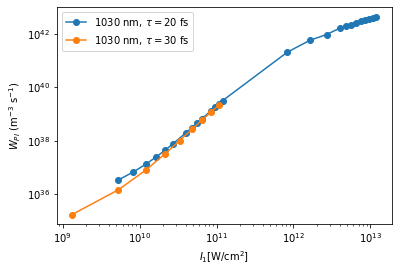

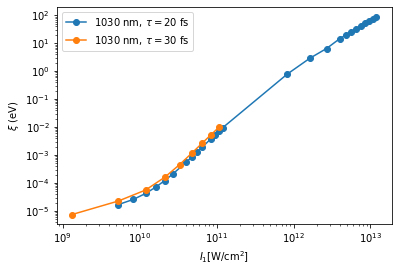

In [39]:
from scipy.constants import c, epsilon_0
plt.figure()
plt.loglog(1E-4*0.5*c*epsilon_0*data1.Efield1**2, data1.Wpi_afterpulse, "-o", label=r"1030 nm, $\tau=20$ fs")
plt.loglog(1E-4*0.5*c*epsilon_0*data1_2.Efield1**2, data1_2.Wpi_afterpulse, "-o", label=r"1030 nm, $\tau=30$ fs")
# plt.xlabel(r"$E_1$[V/m]")
plt.xlabel(r"$I_1$[W/cm$^{2}$]")
plt.ylabel(r"$W_{PI}$ (m$^{-3}$ s$^{-1}$)")
plt.legend()
plt.show()

plt.figure()
plt.loglog(1E-4*0.5*c*epsilon_0*data1.Efield1**2, data1.Energy_afterpulse_eV, "-o", label=r"1030 nm, $\tau=20$ fs")
plt.loglog(1E-4*0.5*c*epsilon_0*data1_2.Efield1**2, data1_2.Energy_afterpulse_eV, "-o", label=r"1030 nm, $\tau=30$ fs")
# plt.xlabel(r"$E_1$[V/m]")
plt.xlabel(r"$I_1$[W/cm$^{2}$]")
plt.ylabel(r"$\xi$ (eV)")
plt.legend()
plt.show()

# The erroneous runs originated from "delay". It seems to have a role on the "afterpulse" instant selection. 

## Single pulse, results at $\tau=20$ fs
### Effect of wavelength

In [57]:
datatmp=datafull
# datatmp=data[data.PolarizationAngle>0]
datatmp=datatmp[datatmp.lambda1==515e-9]
datatmp=datatmp[datatmp.Efield2==0]
datatmp=datatmp[datatmp.CEP1==0]
# datatmp=datatmp[datatmp.STH==3]
datatmp=datatmp[datatmp.tau1==20e-15]
data2 = datatmp
# plt.loglog(Efield, Wpi, "v")
# plt.semilogx(JobID, RunDate_t)
# datafield1=datatmp[datatmp.Efield1==3E9]
# datafield2=datatmp[datatmp.Efield1==9E9]

In [58]:
datatmp

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
230,5109649.0,20180601.0,24.0,0.434637,5.150000e-07,2.000000e-14,1.000000e+08,0.0,0.0,5.150000e-07,...,0.000155,0.000694,-8.547189e+11,5.823872e+24,2.856741e+38,2.911936e+38,3.0,2.0,3762.5,897.845948
1246,8715209.0,20190627.0,24.0,0.434637,5.150000e-07,2.000000e-14,5.000000e+08,0.0,0.0,5.150000e-07,...,0.003139,0.019275,-1.380385e+12,1.477673e+26,7.368815e+39,7.388364e+39,3.0,2.0,3125.0,897.845948
1430,8918132.0,20190709.0,24.0,0.434637,5.150000e-07,2.000000e-14,7.500000e+08,0.0,0.0,5.150000e-07,...,0.008037,0.053554,1.571800e+13,3.726308e+26,1.860877e+40,1.863154e+40,3.0,2.0,3000.0,897.845948
1096,5027635.0,20180525.0,24.0,0.434637,5.150000e-07,2.000000e-14,1.000000e+09,0.0,0.0,5.150000e-07,...,0.018972,0.121628,-4.817450e+13,7.792333e+26,3.895180e+40,3.896167e+40,3.0,2.0,2725.0,897.845948
1564,8918133.0,20190709.0,24.0,0.434637,5.150000e-07,2.000000e-14,1.500000e+09,0.0,0.0,5.150000e-07,...,0.051925,0.405591,9.559337e+13,2.279025e+27,1.138976e+41,1.139513e+41,3.0,2.0,2875.0,897.845948
1405,8649981.0,20190622.0,24.0,0.434637,5.150000e-07,2.000000e-14,2.000000e+09,0.0,0.0,5.150000e-07,...,0.111210,0.906773,1.581342e+14,4.757788e+27,2.377285e+41,2.378894e+41,3.0,2.0,3000.0,897.845948
1541,8715213.0,20190627.0,24.0,0.434637,5.150000e-07,2.000000e-14,3.000000e+09,0.0,0.0,5.150000e-07,...,0.204543,1.984661,2.258693e+14,9.294298e+27,4.641914e+41,4.647149e+41,3.0,2.0,3000.0,897.845948
1462,8715214.0,20190627.0,24.0,0.434637,5.150000e-07,2.000000e-14,4.000000e+09,0.0,0.0,5.150000e-07,...,0.340320,3.612577,2.309676e+14,1.509498e+28,7.541152e+41,7.547492e+41,3.0,2.0,2750.0,897.845948
126,5027636.0,20180525.0,24.0,0.434637,5.150000e-07,2.000000e-14,5.000000e+09,0.0,0.0,5.150000e-07,...,0.455719,6.042565,-3.677350e+14,2.194647e+28,1.097654e+42,1.097324e+42,3.0,2.0,2400.0,897.845948
1027,5027637.0,20180525.0,24.0,0.434637,5.150000e-07,2.000000e-14,1.000000e+10,0.0,0.0,5.150000e-07,...,1.446704,41.685514,-4.019898e+15,6.248507e+28,3.126264e+42,3.124253e+42,3.0,2.0,2112.5,897.845948


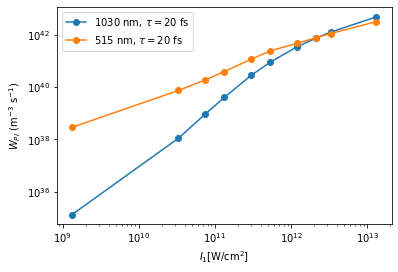

In [59]:
plt.figure()
plt.loglog(1E-4*0.5*c*epsilon_0*data1.Efield1**2, data1.Wpi_afterpulse, "-o", label=r"1030 nm, $\tau=20$ fs")
plt.loglog(1E-4*0.5*c*epsilon_0*data2.Efield1**2, data2.Wpi_afterpulse, "-o", label=r"515 nm, $\tau=$20 fs")
# plt.xlabel(r"$E_1$[V/m]")
plt.xlabel(r"$I_1$[W/cm$^{2}$]")
plt.ylabel(r"$W_{PI}$ (m$^{-3}$ s$^{-1}$)")
plt.legend()
plt.show()

# Bicolor excitation rates

We are looking for the set of bicolor runs available for comparison with experiments

## 1030 nm + 515 nm  at equal fields (1-2-3 cycles)

In [35]:
from scipy.constants import pi
import numpy as np
# data[data.tau1==20e-15]

## NON-NORMALIZED WAVELENGTH AND PULSE DURATION 

datatmp=datafull
# datatmp=data[data.PolarizationAngle>0]
datatmp=datatmp[datatmp.lambda1==1030e-9]
datatmp=datatmp[np.fabs(datatmp.lambda2-datatmp.lambda1/2.)<1E-9] #precise filter for lambda1/2=lambda2
# datatmp=datatmp[np.fabs(datatmp.tau1-4.5630525835309716e-15)<1E-15] #1 cycle for normalized 1030 nm
# datatmp=datatmp[np.fabs(datatmp.tau1-2*4.5630525835309716e-15)<1E-15] #2 cycles for normalized 1030 nm
# datatmp=datatmp[np.fabs(datatmp.tau1-3*4.5630525835309716e-15)<1E-15] #3 cycle for normalized 1030 nm
# datatmp=datatmp[np.fabs(datatmp.tau1-10e-15)<1E-15] #10 fs for normalized 1030 nm
# datatmp=datatmp[np.fabs(datatmp.tau1-20e-15)<1E-15] #20 fs for normalized 1030 nm
datatmp=datatmp[np.fabs(datatmp.tau1-30e-15)<1E-15] #30 fs for normalized 1030 nm
datatmp=datatmp[datatmp.Efield2>0]
datatmp=datatmp[datatmp.Efield1==datatmp.Efield2]
# datatmp=datatmp[datatmp.STH==3]
datatmp=datatmp[datatmp.CEP1==0]
# datatmp=datatmp[datatmp.CEP2==-pi/2.]
data3=datatmp
# datatmp=datatmp[datatmp.CEP2==0] ## INSUFFICIENT DATA FOR THIS CASE
# data=data[data.lambda1==3200e-9]
# datatmp=datatmp[datatmp.Efield1==1E9]

## CAPTURING DATA for NORMALIZED FIELD

datatmp=datafull
# datatmp=data[data.PolarizationAngle>0]
datatmp=datatmp[np.fabs(datatmp.lambda1-1.367968e-6)<1e-9]
# datatmp=datatmp[datatmp.lambda1==1030e-9]
datatmp=datatmp[np.fabs(datatmp.lambda2-datatmp.lambda1/2.)<1E-9]
datatmp=datatmp[np.fabs(datatmp.tau1-4.5630525835309716e-15)<1E-15] #1 cycle for normalized 1030 nm
# datatmp=datatmp[np.fabs(datatmp.tau1-2*4.5630525835309716e-15)<1E-15] #2 cycles for normalized 1030 nm
# datatmp=datatmp[np.fabs(datatmp.tau1-3*4.5630525835309716e-15)<1E-15] #3 cycle for normalized 1030 nm
# datatmp=datatmp[np.fabs(datatmp.tau1-10e-15)<1E-15] #10 fs for normalized 1030 nm
# datatmp=datatmp[np.fabs(datatmp.tau1-20e-15)<1E-15] #20 fs for normalized 1030 nm
# datatmp=datatmp[np.fabs(datatmp.tau1-30e-15)<1E-15] #30 fs for normalized 1030 nm

datatmp=datatmp[datatmp.Efield2>0]
datatmp=datatmp[datatmp.Efield1==datatmp.Efield2]
# datatmp=datatmp[datatmp.STH==3]
datatmp=datatmp[datatmp.CEP1==0]
# datatmp=datatmp[datatmp.CEP2==-pi/2.]
data4=datatmp

In [36]:
set(data4.tau1)

{4.563e-15}

In [37]:
data4

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2380,511469.0,20210825.0,24.0,0.434637,0.000001,4.563000e-15,1.000000e+08,0.0,0.0,6.839800e-07,...,0.0,0.000047,-2.489246e+13,1.130175e+23,2.355116e+37,2.476824e+37,3.0,2.0,1508.75,377.28344
2381,509536.0,20210821.0,24.0,0.434637,0.000001,4.563000e-15,1.000000e+08,0.0,0.0,6.839800e-07,...,0.0,0.000071,-2.525484e+13,1.064828e+23,2.214367e+37,2.333614e+37,3.0,2.0,1508.75,377.28344
2340,511472.0,20210825.0,24.0,0.434637,0.000001,4.563000e-15,2.000000e+08,0.0,0.0,6.839800e-07,...,0.0,0.000189,-5.008518e+13,1.089630e+24,2.304192e+38,2.387969e+38,3.0,2.0,1508.75,377.28344
2341,509537.0,20210821.0,24.0,0.434637,0.000001,4.563000e-15,2.000000e+08,0.0,0.0,6.839800e-07,...,0.0,0.000285,-5.103438e+13,1.012699e+24,2.137853e+38,2.219371e+38,3.0,2.0,1508.75,377.28344
2386,509538.0,20210821.0,24.0,0.434637,0.000001,4.563000e-15,3.000000e+08,0.0,0.0,6.839800e-07,...,0.0,0.000682,-7.788826e+13,4.489489e+24,9.685320e+38,9.838899e+38,3.0,2.0,1508.75,377.28344
2387,511475.0,20210825.0,24.0,0.434637,0.000001,4.563000e-15,3.000000e+08,0.0,0.0,6.839800e-07,...,0.0,0.000475,-7.655963e+13,4.884401e+24,1.055284e+39,1.070436e+39,3.0,2.0,1508.75,377.28344
2410,511478.0,20210825.0,24.0,0.434637,0.000001,4.563000e-15,4.000000e+08,0.0,0.0,6.839800e-07,...,0.0,0.001020,-1.045690e+14,1.458221e+25,3.180530e+39,3.195751e+39,3.0,2.0,1508.75,377.28344
2411,509539.0,20210821.0,24.0,0.434637,0.000001,4.563000e-15,4.000000e+08,0.0,0.0,6.839800e-07,...,0.0,0.001352,-1.059240e+14,1.324602e+25,2.886790e+39,2.902919e+39,3.0,2.0,1508.75,377.28344
2324,511481.0,20210825.0,24.0,0.434637,0.000001,4.563000e-15,5.000000e+08,0.0,0.0,6.839800e-07,...,0.0,0.001989,-1.348823e+14,3.410761e+25,7.467746e+39,7.474822e+39,3.0,2.0,1508.75,377.28344
2325,509540.0,20210821.0,24.0,0.434637,0.000001,4.563000e-15,5.000000e+08,0.0,0.0,6.839800e-07,...,0.0,0.002419,-1.353829e+14,3.066231e+25,6.711141e+39,6.719770e+39,3.0,2.0,1508.75,377.28344


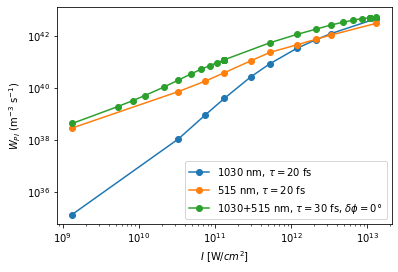

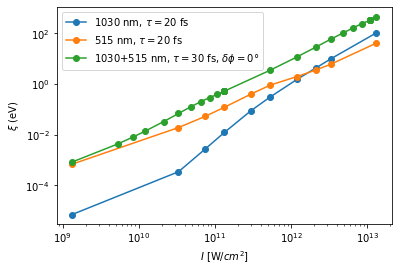

In [38]:
plt.figure()
plt.loglog(1E-4*0.5*c*epsilon_0*data1.Efield1**2, data1.Wpi_afterpulse, "-o", label=r"1030 nm, $\tau=20$ fs")
plt.loglog(1E-4*0.5*c*epsilon_0*data2.Efield1**2, data2.Wpi_afterpulse, "-o", label=r"515 nm, $\tau=20$ fs")
plt.loglog(1E-4*0.5*c*epsilon_0*data3.Efield1**2, data3.Wpi_afterpulse, "-o", label=r"1030+515 nm, $\tau=30$ fs, $\delta \phi = 0°$")
# plt.xlabel(r"$E$ [V/m]")
plt.xlabel(r"$I$ [W/$cm^{2}$]")
plt.ylabel(r"$W_{PI}$ (m$^{-3}$ s$^{-1}$)")
plt.legend()
plt.show()

plt.figure()
plt.loglog(1E-4*0.5*c*epsilon_0*data1.Efield1**2, data1.Energy_afterpulse_eV, "-o", label=r"1030 nm, $\tau=20$ fs")
plt.loglog(1E-4*0.5*c*epsilon_0*data2.Efield1**2, data2.Energy_afterpulse_eV, "-o", label=r"515 nm, $\tau=20$ fs")
plt.loglog(1E-4*0.5*c*epsilon_0*data3.Efield1**2, data3.Energy_afterpulse_eV, "-o", label=r"1030+515 nm, $\tau=30$ fs, $\delta \phi = 0°$")
# plt.xlabel(r"$E$ [V/m]")
plt.xlabel(r"$I$ [W/$cm^{2}$]")
plt.ylabel(r"$\xi$ (eV)")
plt.legend()
plt.show()

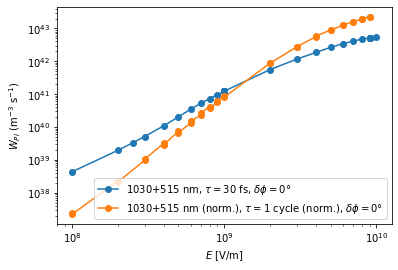

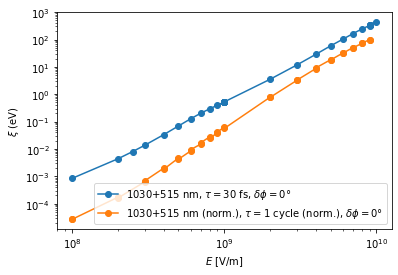

In [39]:
plt.figure()
plt.loglog(data3.Efield1, data3.Wpi_afterpulse, "-o", label=r"1030+515 nm, $\tau=30$ fs, $\delta \phi = 0°$")
plt.loglog(data4.Efield1, data4.Wpi, "-o", label=r"1030+515 nm (norm.), $\tau=1$ cycle (norm.), $\delta \phi = 0°$")
plt.xlabel(r"$E$ [V/m]")
plt.ylabel(r"$W_{PI}$ (m$^{-3}$ s$^{-1}$)")
plt.legend()
plt.show()

plt.figure()
plt.loglog(data3.Efield1, data3.Energy_afterpulse_eV, "-o", label=r"1030+515 nm, $\tau=30$ fs, $\delta \phi = 0°$")
plt.loglog(data4.Efield1, data4.Energy_eV, "-o", label=r"1030+515 nm (norm.), $\tau=1$ cycle (norm.), $\delta \phi = 0°$")
plt.xlabel(r"$E$ [V/m]")
plt.ylabel(r"$\xi$ (eV)")
plt.legend()
plt.show()

# Preparing pulses for conserving number of cycles

In [40]:
# from scipy.fft import fft, fftfreq, fftshift
from numpy import fft
import numpy as np
from scipy.constants import c, hbar, e
import matplotlib.pyplot as plt

# del t, y
# number of signal points
N = 10_000 #this controls timestep, it does not control time window duration. Then it acts only on the maximum energy one can address in Fourier spectrum

wavelength = 1.3679687500000002e-06; tau=4.5630525835309716e-15 #1 cycle of 1030 nm renormalized with LDA->EXP band gap
# wavelength=2000e-9; tau=15e-15 #Kozak experimental for angle dependence, pulse rescaled for TDDFT LDA
# wavelength = 2656e-9; tau=13e-15 #Kozak experimental, pulse rescaled for TDDFT LDA
#wavelength = 3200e-9; tau=30e-15 #Pulse used for orientation-dep excitation rate
CEP=0e0 #1*pi

omega = 2*np.pi*c/wavelength
T = 2*np.pi/omega

print("One-cycle period: "+str(T)+" seconds")
print("Frequency in Hz:  "+str(omega/1E15)+" PHz")
print("Number of cycles: "+str(tau/T)+" cycles")

One-cycle period: 6.671281903963041e-15 seconds
Frequency in Hz:  0.9418257836544266 PHz
Number of cycles: 2.248443435 cycles


## Gaussian pulses

In [36]:
t0 = 2*tau #central time
tmin = 0; tmax = 15*t0; #size of the window: controls energy precision. 
# Solution for increasing FFT spectrum precision: increase size of initial signal table, just fill it with zeros.
t = np.linspace(tmin, tmax, N, endpoint=False)
TimeStep=np.diff(t)[0]
print("Timestep: "+str(TimeStep)+" s")
# print(omega*t)
## TODO: replace with pulse from spp_extended_theory STH !
sigma_tau=tau/(2.*np.sqrt(2.*np.log(2.)))
y = np.exp(-0.5*((t-t0)/sigma_tau)**2) * np.sin(omega*t+CEP) #+ 0.5*np.sin(80.0 * 2.0*np.pi*t)
# y.resize(30000,)

Timestep: 4.5e-17 s


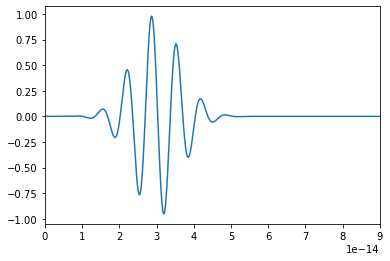

In [37]:
plt.figure()
plt.plot(t,y)
# plt.plot(Envelope[0],Envelope[1])
plt.xlim([0,6*tau])
plt.show()

In [29]:
from scipy.constants import epsilon_0
0.5*c*epsilon_0*(1E9)**2 / 1E11 /1E4

1.3272093639964782

It is well seen that Gaussian pulses never fall to zero at the beginning of the pulse. 

## Generation of STH pulse, same as in octopus

In [41]:
# from octopus_slabs.Pulses.GeneratePulse import GeneratePulse
from spp_extended_theory.Keldysh.libKeldyshPulses import PulseSmoothTopHatShape
from scipy.constants import pi

# wavelength=1030e-9
RiseCycle=2
PulseDelay=0e0
power=2

omega = 2.*pi*c/wavelength
tauRise = 2.*pi*RiseCycle / (omega)
print("Rise cycle duration: ", tauRise, "seconds")
ComputingT = 8./5.*(tauRise+tau+tauRise+PulseDelay)
print("Computing physical time range: ", ComputingT, "seconds")
PeakField = 1E9


tmin = 0e-15
tmax = float(ComputingT)
Number = 50000 #NOTE: better to put too many nodes here ! Better to have something wider than planned octopus time steps. 
timestep=(tmax-tmin)/(Number+1.)
t = np.arange(tmin, tmax, timestep)
tauSafe = wavelength / c #1 optical cycle to ensure having dA/dt = 0 at instant zero !
Envelope, Field = PulseSmoothTopHatShape(t, tau, tauRise, PeakField, wavelength, CEP, t0+tauSafe, PulseDelay, power)
# Envelope     = GeneratePulse(t, tau, tauRise, PeakField, wavelength, 2.*pi*CEP, tau/2.+tauRise+tauSafe, PulseDelay+0.1E-15, power)
# print(Field)

Rise cycle duration:  1.3342563807926082e-14 seconds
Computing physical time range:  6.669620418536347e-14 seconds


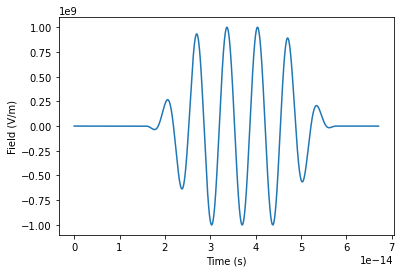

In [39]:
plt.figure()
plt.plot(t,np.real(Field))
# plt.plot(Envelope[0]*timestep,Envelope[1])
plt.xlabel("Time (s)")
plt.ylabel("Field (V/m)")
# plt.xlim([0,6*tau])
plt.show()

## Normalization of wavelength to bandgap

Each pulse should be renormalized to the functional band gap energy

$\frac {\hbar \omega_{th}} {E_g^{LDA}} = \frac{\hbar \omega_{exp}}{ E_g^{exp} }$

In [42]:
wavelength_exp = 2000e-9 #or 2300e-9 ? 
Eg_exp = 3.4*e #direct band gap at 300 K
Eg_th  = 2.56*e

wavelength_th = Eg_exp/Eg_th * wavelength_exp

print(wavelength_th)

2.6562499999999998e-06


### Deducing pulse duration from normalized wavelength

In [43]:
number_cycles = 3.747405725 #cycles

omega_exp = 2*pi*c/wavelength_exp
omega_th = 2*pi*c/wavelength_th

T_exp = 2*np.pi/omega_exp
T_th  = 2*np.pi/omega_th

tau_th = number_cycles * T_th
print("Renormalized pulse duration: ", tau_th)

Renormalized pulse duration:  3.3203125e-14


In [26]:
1.3679687500000002e-06/2

6.839843750000001e-07